Importing libraries

In [79]:
import pandas as pd
import numpy as np
import matplotlib as mp
import matplotlib.pyplot as plt

importing dataset

In [80]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/TIH_Data/yield_df.csv')

yearly_yield = df.groupby('Year')['hg/ha_yield'].sum().reset_index()

print(yearly_yield.head())

X = yearly_yield['Year'].values.reshape(-1, 1)
y = yearly_yield['hg/ha_yield'].values.reshape(-1, 1)

   Year  hg/ha_yield
0  1990     77344486
1  1991     77194758
2  1992     81570324
3  1993     82528465
4  1994     83658971


ploting the X and y

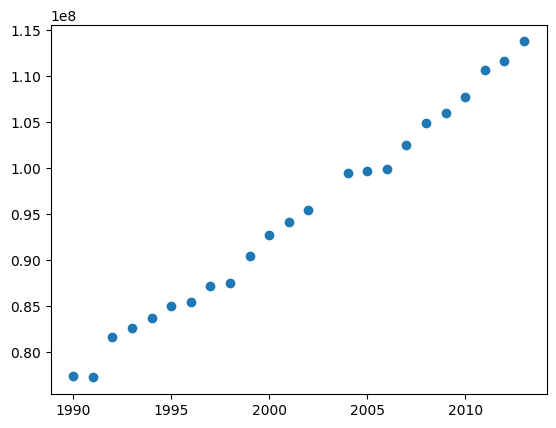

In [81]:
mp.pyplot.scatter(X,y)

Normalinzin the Years before applying linear regression

In [82]:
XMean = np.mean(X)
XStd = np.std(X)
X = (X - np.mean(X)) / np.std(X)

The Linear Regression Model

In [83]:
w = 0.0
b = 0.0
lr = 0.01
epochs = 150
loss = []
for epoch in range(epochs):
  err=w*X+b-y
  w-=lr*2*(err*X).mean(); b-=lr*2*err.mean()
  loss.append((err**2).mean())

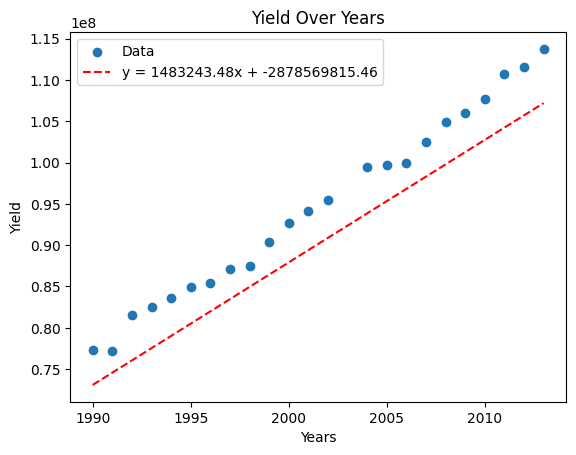

In [84]:

X_orig = (X * XStd) + XMean

w_orig = w / XStd
b_orig = b - (w * XMean / XStd)

mp.pyplot.scatter(X_orig, y, label='Data')
mp.pyplot.plot(X_orig, w_orig * X_orig + b_orig, color='red', linestyle='--',
               label=f'y = {w_orig:.2f}x + {b_orig:.2f}')

mp.pyplot.xlabel('Years')
mp.pyplot.ylabel('Yield')
mp.pyplot.title('Yield Over Years')
mp.pyplot.legend()
mp.pyplot.show()

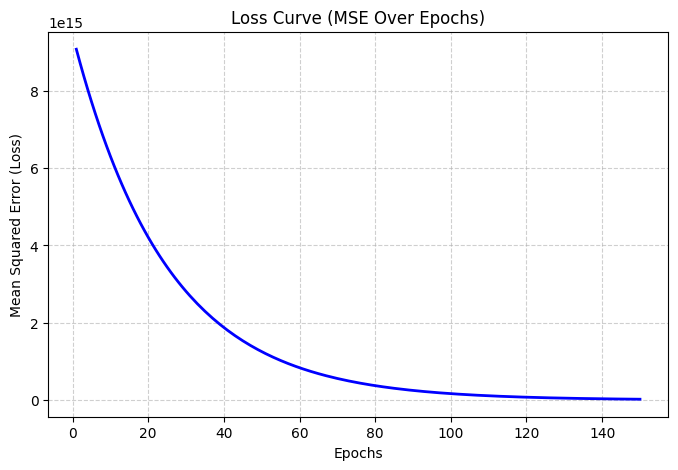

In [85]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), loss, color='blue', linewidth=2)
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error (Loss)')
plt.title('Loss Curve (MSE Over Epochs)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()